## Problem statement

Survival Analysis is a detailed study of the factors that are associated with the survival of people in an emergency. It helps to understand which characteristics (who they are, how they travel, what they pay) made some people more likely to survive than others, and makes it easier to design better protocols, to prioritize resources and to learn lessons for future situations.

For example, instead of assuming who is most at risk, an organization can analyze which groups had the highest and the lowest survival rates, and then focus its prevention and rescue measures on them.

In this practice we build a model to predict whether a passenger survived, using the passengers of the Titanic (`Titanic-Dataset.csv`, 891 passengers, 12 variables). The target variable is `Survived` (0 = did not survive, 1 = survived). Unlike the previous practice, where we predicted a number (the price of a house), here the target is a **category**, so it is a **classification** problem.

> ## Notebook for students
>
> This is the same practice as the reference one, but **you decide the conclusions** of the exploratory analysis and, from them, you complete the **data cleaning**, the **feature selection** and the **feature engineering**.
>
> - The cells marked with **YOUR TURN** are the ones you have to complete (text and code).
> - The rest of the notebook is already written.
> - The notebook **runs from top to bottom without errors even if you have not completed your parts**: where the data goes from one dataframe to the next one (`df_clean`, `df_selected`, `df_encoded`...), the dataframe is just copied. In that case the model is trained with a **minimal baseline** (only the columns that are already numeric and have no nulls), and a message tells you what is missing.
> - **Your goal is to improve the baseline:** the better you clean, select and engineer the features, the better the model will perform on the test set.
> - Everything that is learned from the data (a median, a most frequent value...) must be learned from the **training set** (`df_train`) and then applied, in the same way, to the **test set** (`df_test`).
> - Write the text in the same style as the rest of the notebook: **Decision** and **Why** for each step.

# 0. Loading dataset

Before any analysis we load the data, we remove the rows that can never be used, and we separate the **test set**, which we do not touch until the final evaluation.

> **Why so early?** Everything that we learn by looking at the data (the median used to fill a null, the variables we keep...) must be learned from the **training set only**. If the test set takes part in those decisions, it stops being "data that the model has not seen" and the final results look better than they really are (*data leakage*).

## 0.1 Loading dataset

In [98]:
import numpy as np
import pandas as pd
from pathlib import Path

CSV_PATH = Path("Titanic-Dataset.csv")

# On Google Colab, if the file is not in the environment, upload it manually
if not CSV_PATH.exists():
    try:
        from google.colab import files
        files.upload()  # select Titanic-Dataset.csv
    except ImportError:
        raise FileNotFoundError(f"File not found: {CSV_PATH.resolve()}")

df_raw = pd.read_csv(CSV_PATH)
print(f"Dataset loaded: {df_raw.shape[0]} rows x {df_raw.shape[1]} columns")
df_raw.head()

Dataset loaded: 891 rows x 12 columns


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 0.2 Remove duplicates and 0/null in the target variable

We remove two kinds of rows **before** splitting, because removing them does not learn anything from the data:
- **Exact duplicates.** They carry no new information and, if one copy fell in the training set and the other in the test set, the model would have "already seen" that passenger: a direct data leakage. `PassengerId` is different in every row, so we ignore it when we look for duplicates.
- **Rows whose target is null.** A row without the target cannot be used to train the model or to evaluate it.

In this dataset there is nothing to remove, but the step is part of any pipeline, and the code checks it.

> The nulls of the **features** are not handled here: they are filled with a value learned from the data (a median, a mode), so that has to be done after the split, using the training set only.

In [99]:
# YOUR TURN: remove the exact duplicates (ignoring PassengerId, which is different in every row) and the rows without a valid target.
# For now, the dataframe is just copied, so the notebook can run:
df = df_raw.copy()

df.drop_duplicates(subset=[c for c in df_raw.columns if c != "PassengerId"])
df.dropna(subset=["Survived"])

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


## 0.3 Separate train and test

We split the data into a **training set** (80%) and a **test set** (20%):
- The **training set** is where we do the whole analysis and where the model learns. From now on, it is the only data we look at.
- The **test set** is kept apart and is used **only once, at the end**, to measure how the model behaves with passengers it has not seen.

Two details of the split:
- **Stratified (`stratify`):** in a classification problem the split must keep the same proportion of passengers who survived in both sets. If not, by chance, one of them could have many more survivors than the other and the results would not be comparable.
- **`random_state`:** a fixed seed so the split is always the same and the results can be reproduced.

> Later, to compare models and to tune them, we will use cross-validation inside the training set, but the test set is never used for that.

In [100]:
from sklearn.model_selection import train_test_split

df_train, df_test = train_test_split(df, test_size=0.2, random_state=42, stratify=df["Survived"])

print(f"Training set: {len(df_train)} rows, proportion of survivors = {df_train['Survived'].mean():.3f}")
print(f"Test set:     {len(df_test)} rows, proportion of survivors = {df_test['Survived'].mean():.3f}")

Training set: 712 rows, proportion of survivors = 0.383
Test set:     179 rows, proportion of survivors = 0.385


# 1. EDA (Exploratory Data Analysis)

Exploratory data analysis built progressively on the **training set** (`df_train`). The test set (`df_test`) is not used in this analysis.

## 1.1 First look at the data

Structure, types and summary statistics.

In [101]:
# Structure: column names, dtypes and non-null counts
df_train.info()

# Summary statistics for numerical columns
display(df_train.describe())

# Summary for categorical (text) columns
display(df_train.describe(include=["object", "string"]))


<class 'pandas.core.frame.DataFrame'>
Index: 712 entries, 692 to 507
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  712 non-null    int64  
 1   Survived     712 non-null    int64  
 2   Pclass       712 non-null    int64  
 3   Name         712 non-null    object 
 4   Sex          712 non-null    object 
 5   Age          575 non-null    float64
 6   SibSp        712 non-null    int64  
 7   Parch        712 non-null    int64  
 8   Ticket       712 non-null    object 
 9   Fare         712 non-null    float64
 10  Cabin        160 non-null    object 
 11  Embarked     710 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 72.3+ KB


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,712.000000,712.000000,712.000000,575.000000,712.000000,712.000000,712.000000
mean,444.405899,0.383427,2.308989,29.807687,0.492978,0.390449,31.819826
std,257.465527,0.486563,0.833563,14.485211,1.060720,0.838134,48.059104
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,222.750000,0.000000,2.000000,21.000000,0.000000,0.000000,7.895800
50%,439.500000,0.000000,3.000000,28.500000,0.000000,0.000000,14.454200
75%,667.250000,1.000000,3.000000,39.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


,Name,Sex,Ticket,Cabin,Embarked
count,712,712,712,160,710
unique,712,2,571,127,3
top,"Lam, Mr. Ali",male,1601,G6,S
freq,1,459,6,4,516


### 1.1.1 Types of variables

Variables can be **numerical** or **categorical**. Numerical variables can be **continuous** or **discrete**, and categorical variables can be **nominal** or **ordinal**. Each type is usually analyzed separately, because the questions we ask and the plots that make sense are different:

| Type | Description | Examples in this dataset | What to look at | Typical plots |
|---|---|---|---|---|
| Numerical, continuous | Can take any value in a range | `Age`, `Fare` | Shape of the distribution, skewness, central tendency (mean vs. median), spread, outliers | Histogram (+ KDE), boxplot |
| Numerical, discrete | Takes a few integer values (counts) | `SibSp`, `Parch` | Frequency of each value, most common value, rare values | Count plot (bar chart) |
| Categorical, nominal | Labels with no natural order (binary variables are a particular case) | `Sex`, `Embarked` (and the target `Survived`, which is binary) | Number of classes, frequency and percentage of each class, imbalanced classes | Count plot, class proportions (%) |
| Categorical, ordinal | Labels with a meaningful order, but the distance between them is not measurable | `Pclass` (1st > 2nd > 3rd class) | Same as nominal, keeping the logical order of the classes | Count plot with ordered bars, class proportions (%) |
| Identifiers and free text | Almost one different value per row | `PassengerId`, `Name`, `Ticket`, `Cabin` | Number of different values and nulls: they are not analyzed as variables | Table |

The distinction between nominal and ordinal matters later for encoding: binary variables can be mapped to 0/1, ordinal variables can be encoded respecting their order, and nominal variables with more than two classes need one-hot encoding (`Embarked` is one of them).

The univariate analysis (section 1.2) follows this order:
1. The **missing values**.
2. The **target** (`Survived`): class balance.
3. The **numerical** features (continuous `Age` and `Fare`, discrete `SibSp` and `Parch`).
4. The **categorical** features (nominal `Sex` and `Embarked`, ordinal `Pclass`).
5. The **identifiers and free text** variables.

In [102]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

target = "Survived"

# Numerical features
cont_cols = ["Age", "Fare"]  # continuous
disc_cols = ["SibSp", "Parch"]  # discrete

# Categorical features
nominal_cols = ["Sex", "Embarked"]
ordinal_cols = ["Pclass"]
ordinal_order = [3, 2, 1]  # 3rd < 2nd < 1st class

# Identifiers and free text
id_cols = ["PassengerId", "Name", "Ticket", "Cabin"]

## 1.2 Univariate analysis

**Definition:** a univariate analysis is the study of each variable on its own, without looking at its relationship with the rest. It describes how the values of a single variable behave, starting with the target (`Survived`).

**What we are looking for:** above all, to know the distribution of each variable, in order to:
- Check whether it is **skewed** and, if so, decide whether a transformation applies (for example, a log transform).
- Detect **outliers**.
- Examine the **concentration of values** (where most of the data is) and the **gaps** (ranges with no data).
- Spot **imbalanced classes** in categorical variables. In a classification problem this also applies to the **target**: if one class is much bigger than the other, the model can look good just by always predicting the big one.

In this section we show the plots of each variable.

> **Warning:** missing values (nulls) do not appear in the plots. Seaborn and matplotlib ignore them, so the bars only count the rows that have a value. Always check the missing values (section 1.2.1) alongside these plots.

### 1.2.1 Identify Missing values

A missing value (null) is a piece of data that is absent. It is not a variable, but it affects every analysis: nulls do not appear in the plots, and most models cannot work with them. Here we only measure them; what to do with them is decided later, in the data cleaning. The nulls of the target were already checked in section 0.2.

**What we look for:**
- **Which variables have nulls** and how many.
- **How big the problem is:** a few nulls can be imputed or removed without much impact, but a large share of nulls makes a variable problematic.

Total nulls: 691


,nulls,% nulls
Age,137,19.24
Cabin,552,77.53
Embarked,2,0.28


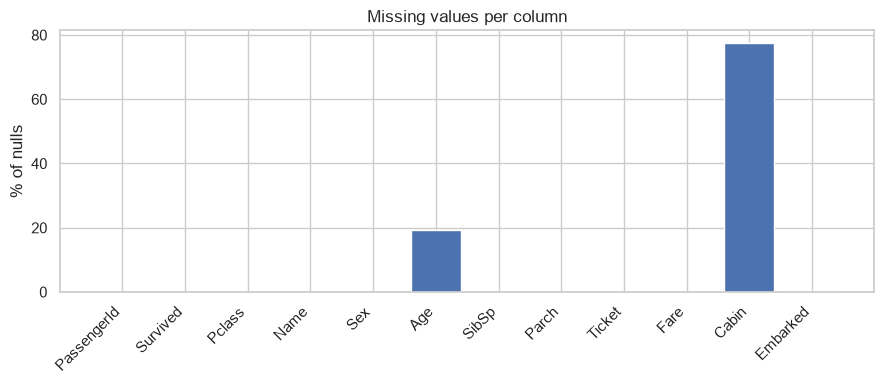

In [103]:
# Number and percentage of nulls in each column
missing = df_train.isna().sum()
missing_table = pd.DataFrame({"nulls": missing, "% nulls": (missing / len(df_train) * 100).round(2)})
print(f"Total nulls: {missing.sum()}")
display(missing_table[missing_table["nulls"] > 0])

# Percentage of nulls per column
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(missing_table.index, missing_table["% nulls"])
ax.set_ylabel("% of nulls")
ax.set_title("Missing values per column")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### 1.2.2 Target univariable analysis

**What we look for:** the balance of the classes of the target, because it decides how we will evaluate the model:
- Whether one class is much **bigger** than the other (**imbalanced classes**). If so, a model that always predicts the big class looks good with the accuracy.
- The percentage of each class, which gives us the **baseline** that the model has to beat.

We use a count plot and the proportion of each class.

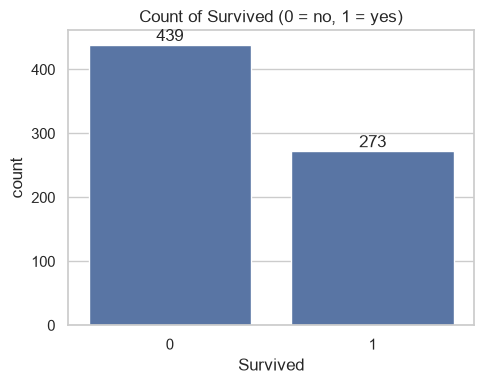

Survived
0    61.7
1    38.3
Name: proportion, dtype: float64


In [104]:
# Target variable: how many passengers survived and how many did not
fig, ax = plt.subplots(figsize=(5, 4))
sns.countplot(x=df_train[target], ax=ax)
ax.bar_label(ax.containers[0])  # show the count above each bar
ax.set_title("Count of Survived (0 = no, 1 = yes)")
plt.tight_layout()
plt.show()

# Class proportions: a model that always predicts the majority class would get this accuracy
print((df_train[target].value_counts(normalize=True) * 100).round(1))

### 1.2.3 Numerical features univariate analysis

**What we look for:**
- In the **continuous** variables (`Age`, `Fare`): the **skewness**, the **outliers**, and the concentration of values and the gaps (histogram with KDE and boxplot).
- In the **discrete** variables (`SibSp`, `Parch`): the **frequency of each value**, which one is the most common and which values are **rare** (very few passengers), because they will give unreliable results later. Since they take few values, we use count plots with the count above each bar.

#### 1.2.3.1 Continuous (`Age`, `Fare`)

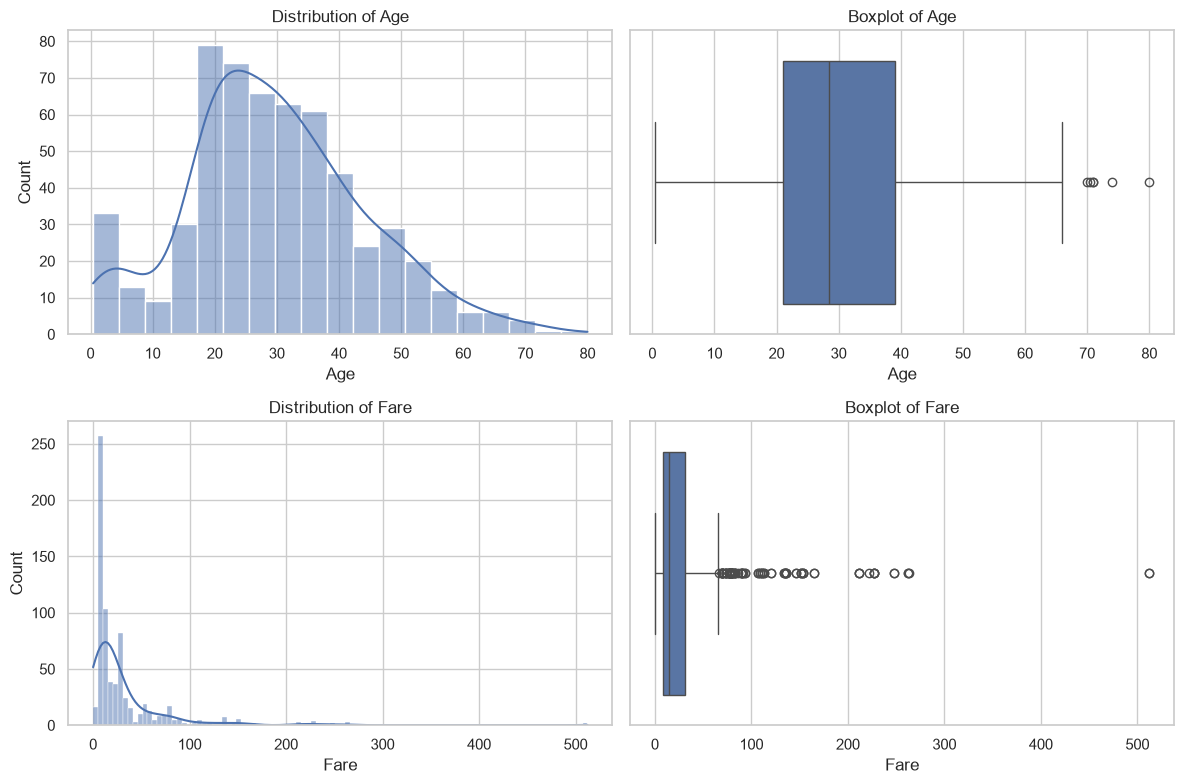

Skewness of Age: 0.35
Skewness of Fare: 4.65

Passengers with Fare = 0: 14
Most expensive fares: [512.33, 512.33, 263.0, 262.38, 262.38, 247.52]


In [105]:
# Continuous features: distribution (histogram + KDE) and outliers (boxplot)
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for row, col in enumerate(cont_cols):
    sns.histplot(df_train[col], kde=True, ax=axes[row, 0])
    axes[row, 0].set_title(f"Distribution of {col}")
    sns.boxplot(x=df_train[col], ax=axes[row, 1])
    axes[row, 1].set_title(f"Boxplot of {col}")

plt.tight_layout()
plt.show()

# Skewness (> 0 means right-skewed) and number of values equal to 0 in Fare
for col in cont_cols:
    print(f"Skewness of {col}: {df_train[col].skew():.2f}")
print(f"\nPassengers with Fare = 0: {(df_train['Fare'] == 0).sum()}")
print(f"Most expensive fares: {df_train['Fare'].nlargest(6).round(2).tolist()}")

#### 1.2.3.2 Discrete (`SibSp`, `Parch`)

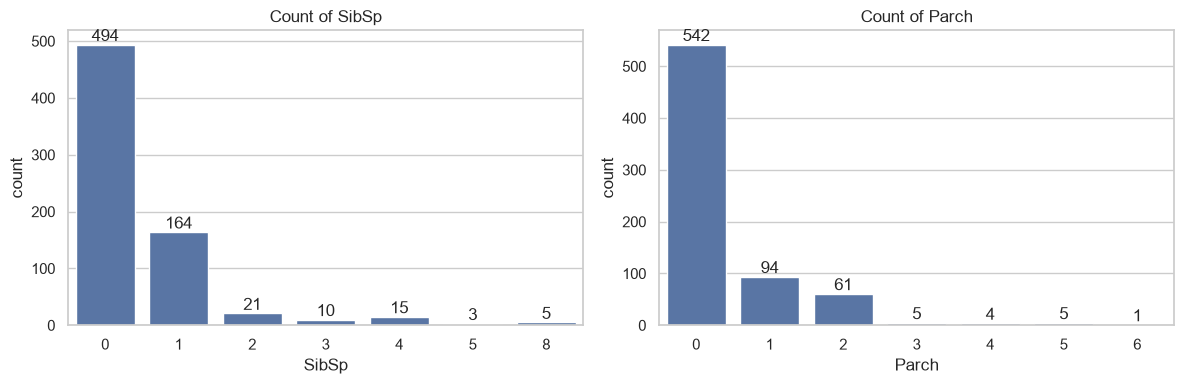

In [106]:
# Discrete features: they take few integer values, so count plots work better than histograms
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, col in zip(axes, disc_cols):
    sns.countplot(x=df_train[col], ax=ax)
    ax.set_title(f"Count of {col}")
    ax.bar_label(ax.containers[0])  # show the count above each bar

plt.tight_layout()
plt.show()

### 1.2.4 Categorical features univariate analysis

**What we look for:**
- The **proportion of each class** and, above all, whether there are **imbalanced classes**: a class that dominates or that is almost empty gives the variable very little information.
- In the **ordinal** variable (`Pclass`) the same, but plotting the classes in their logical order.

We use count plots (with the percentage of each class printed below).

#### 1.2.4.1 Nominal variables (no natural order)

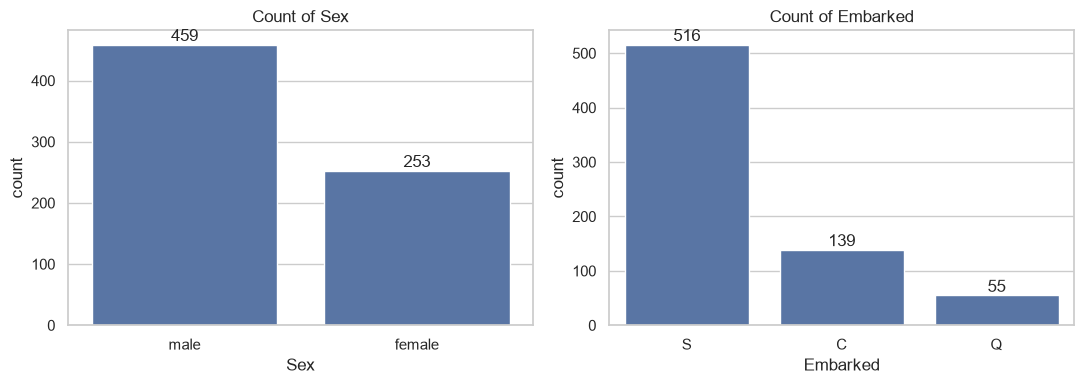


Sex
Sex
male      64.5
female    35.5
Name: proportion, dtype: float64

Embarked
Embarked
S      72.5
C      19.5
Q       7.7
NaN     0.3
Name: proportion, dtype: float64


In [107]:
# Nominal features: count plots to spot imbalanced classes
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, col in zip(axes, nominal_cols):
    sns.countplot(x=df_train[col], ax=ax)
    ax.set_title(f"Count of {col}")
    ax.bar_label(ax.containers[0])  # show the count above each bar

plt.tight_layout()
plt.show()

# Class proportions (%) for each nominal feature (nulls are not counted in the plots, so we show them here)
for col in nominal_cols:
    print(f"\n{col}")
    print((df_train[col].value_counts(normalize=True, dropna=False) * 100).round(1))

#### 1.2.4.2 Ordinal variables (meaningful order)

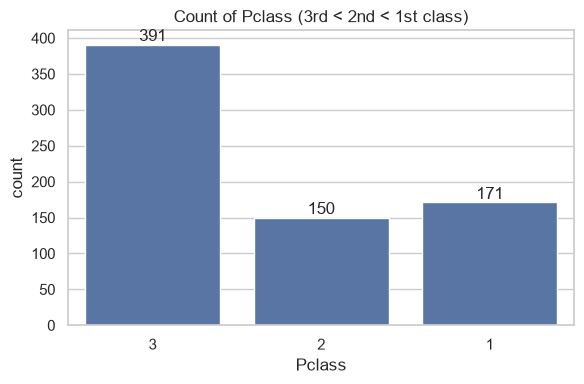

Pclass
3    54.9
2    21.1
1    24.0
Name: proportion, dtype: float64


In [108]:
# Ordinal feature: same plot, but the bars follow the logical order of the classes
fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(x=df_train["Pclass"], order=ordinal_order, ax=ax)
ax.bar_label(ax.containers[0])  # show the count above each bar
ax.set_title("Count of Pclass (3rd < 2nd < 1st class)")
plt.tight_layout()
plt.show()

# Class proportions (%) in the logical order
print((df_train["Pclass"].value_counts(normalize=True)[ordinal_order] * 100).round(1))

### 1.2.5 Identifiers and free text

These variables have almost a different value for each passenger, so a distribution plot makes no sense. We only check how many different values they have and how many nulls.

In [109]:
# Number of different values and nulls of the identifier / free text columns
pd.DataFrame({
    "unique values": df_train[id_cols].nunique(),
    "% unique": (df_train[id_cols].nunique() / len(df_train) * 100).round(1),
    "% nulls": (df_train[id_cols].isna().mean() * 100).round(1),
})

,unique values,% unique,% nulls
PassengerId,712,100.0,0.0
Name,712,100.0,0.0
Ticket,571,80.2,0.0
Cabin,127,17.8,77.5


### 1.2.6 Conclusions of the univariate analysis


Now, **your turn**.

> **YOUR TURN:** write here what you find in the training set, using the plots and the numbers of the previous sections. Write at least one conclusion for each concept that applies to this dataset (the balance of the target, skewness, outliers, concentration of values and gaps, categorical variables, identifiers and missing values).

**Target**
- hay un 61% de no supervivientes y 39 de supervivientes

**Skewness**
- la mayoria tienen una Fare baja

**Outliers**
- fare tiene outliers muy a la derecha 

**Concentration of values and gaps**
- ...

**Categorical variables**
- Sex son 65% hombres

**Identifiers and free text**
- ...

**Missing values**
- Cabin tiene 77% de nulos

#### Actions decided from the conclusions

> **YOUR TURN:** for each finding, decide what you will do and where you will do it. Order the rows by the "Where" column, from the first step that is done to the last one.

| What we found | Action decided | Where |
|---|---|---|
| | | |
| | | |
| | | |
| | | |
| | | |
| | | |

# 2. Data cleaning

In the univariate analysis we diagnosed the problems of the training set. Here you treat them, one decision at a time. The principle is the same as in the split: **everything we learn from the data is learned from the training set** and then applied, in exactly the same way, to the test set.

The duplicated rows and the rows without a target were already handled in section 0.2.

> **YOUR TURN:** fill in the table with the decisions you take (one row per problem), and then apply them in section 2.1.

| Problem | Decision | Why |
|---|---|---|
| | | |
| | | |
| | | |

## 2.1 Apply data cleaning based on the EDA conclusions

> **YOUR TURN:** for each decision of the table, add a subsection (2.1.1, 2.1.2...) with its **Decision**, its **Why** and its code. A good way to do it is to write **one small function per step** and apply it to the training and to the test set, using only values learned from `df_train`.

### 2.1.1 [Problem to solve]

**Decision:** ...

**Why:** ...

In [110]:
# YOUR TURN: write your cleaning steps here.
# Learn the values you need (a median, a most frequent value...) from df_train only, and apply the same steps to both sets.

# For now, the dataframes are just copied, so the notebook can run:
df_clean = df_train.copy()
df_test_clean = df_test.copy()

In [111]:
# rellenar los valores nulos de Age con la media de Age

age_mean = df_train["Age"].mean()

def fill_age(data):
    data = data.copy()
    data["Age"] = data["Age"].fillna(age_mean)
    return data

df_clean = fill_age(df_train)
df_test_clean = fill_age(df_test)

print(f"Mean used to fill Age: {age_mean:.2f}")
print(f"Nulls in Age -> train: {df_clean['Age'].isna().sum()}, test: {df_test_clean['Age'].isna().sum()}")

Mean used to fill Age: 29.81
Nulls in Age -> train: 0, test: 0


### 2.1.2 Final check

**Decision:** compare the datasets before and after cleaning.

**Why:** every cleaning step changes the data, so we verify that it did what we expected and see exactly what we changed in each set.

In [112]:
# Compare the datasets before and after cleaning
for name, before, after in [("Training", df_train, df_clean), ("Test", df_test, df_test_clean)]:
    print(f"{name} set: {len(before)} -> {len(after)} rows, {before.shape[1]} -> {after.shape[1]} columns, "
          f"nulls: {before.isna().sum().sum()} -> {after.isna().sum().sum()}")

df_clean.head()

Training set: 712 -> 712 rows, 12 -> 12 columns, nulls: 691 -> 554
Test set: 179 -> 179 rows, 12 -> 12 columns, nulls: 175 -> 135


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
692,693,1,3,"Lam, Mr. Ali",male,29.807687,0,0,1601,56.4958,NaN,S
481,482,0,2,"Frost, Mr. Anthony Wood ""Archie""",male,29.807687,0,0,239854,0.0000,NaN,S
527,528,0,1,"Farthing, Mr. John",male,29.807687,0,0,PC 17483,221.7792,C95,S
855,856,1,3,"Aks, Mrs. Sam (Leah Rosen)",female,18.000000,0,1,392091,9.3500,NaN,S
801,802,1,2,"Collyer, Mrs. Harvey (Charlotte Annie Tate)",female,31.000000,1,1,C.A. 31921,26.2500,NaN,S


# 3. Multivariate analysis

From now on we work with the cleaned training set (`df_clean`).

**Definition:** a multivariate analysis studies several variables at the same time. Here we look at how the features relate to the target (`Survived`) and **to each other**.

**What we are looking for:**
- Which features are most related to `Survived` when all of them are compared together (correlation matrix).
- **Redundancy between features:** features that are strongly related to each other, so they carry redundant information.

| Question | Tool | Variables |
|---|---|---|
| How strong are all the pairwise relationships? | Correlation matrix (heatmap) | Numerical, discrete and encoded categorical |
| Are the features redundant between them? | Correlation matrix, reading the pairs of features | Features (without the target) |

> **Note:** correlations need numeric variables. Here we only make a **temporary numeric copy** (`df_corr`) for this analysis. The final encoding used for modeling is done later, in *Feature engineering*.

## 3.1 Correlation analysis

### 3.1.1 Temporary numeric copy

The correlation analysis only needs the variables to be **numeric**, so this is the only treatment we apply here: `Sex` becomes 0/1, and `Embarked` (a nominal variable with three classes) becomes one 0/1 column per class, with Southampton as the reference. We do it on a **temporary copy** (`df_corr`), only for this analysis, and `df_clean` is not modified. The encoding used for modeling is decided later, in *Feature engineering*.

In [113]:
# Temporary numeric copy only for the correlation analysis (the final encoding is done in "Features")
# The identifiers and the free text are not numeric, so they are left out of the correlation analysis
text_columns = [c for c in ["Name", "Ticket", "Cabin", "PassengerId"] if c in df_clean.columns]
df_corr = df_clean.drop(columns=text_columns).copy()

# Binary variable: female = 0, male = 1
df_corr["Sex"] = df_corr["Sex"].map({"female": 0, "male": 1})

# Nominal variable with 3 classes: one 0/1 column per class (Southampton is the reference)
df_corr["Embarked_C"] = (df_corr["Embarked"] == "C").astype(int)
df_corr["Embarked_Q"] = (df_corr["Embarked"] == "Q").astype(int)
df_corr = df_corr.drop(columns="Embarked")

df_corr.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked_C,Embarked_Q
692,1,3,1,29.807687,0,0,56.4958,0,0
481,0,2,1,29.807687,0,0,0.0000,0,0
527,0,1,1,29.807687,0,0,221.7792,0,0
855,1,3,0,18.000000,0,1,9.3500,0,0
801,1,2,0,31.000000,1,1,26.2500,0,0


### 3.1.2 Correlation matrix

**What we look for:** every cell is the correlation between two variables (from -1 to 1). The sign says if the relationship is positive or negative, and the color intensity says how strong it is. The matrix contains all the pairs of variables, and we read it in **two ways**:
- **Target vs features:** the row (or column) of `Survived`, to see which features are most related to the target (section 3.2).
- **Features vs features:** the rest of the matrix, to see which features are related to each other (section 3.3).

> Pearson correlation measures **linear** relationships. With a binary target and binary or ordinal features it is a reasonable approximation, but it should be read as an orientation, not as an exact measure. The sign depends on the encoding: for example, `Sex` is negative because we coded men as 1.

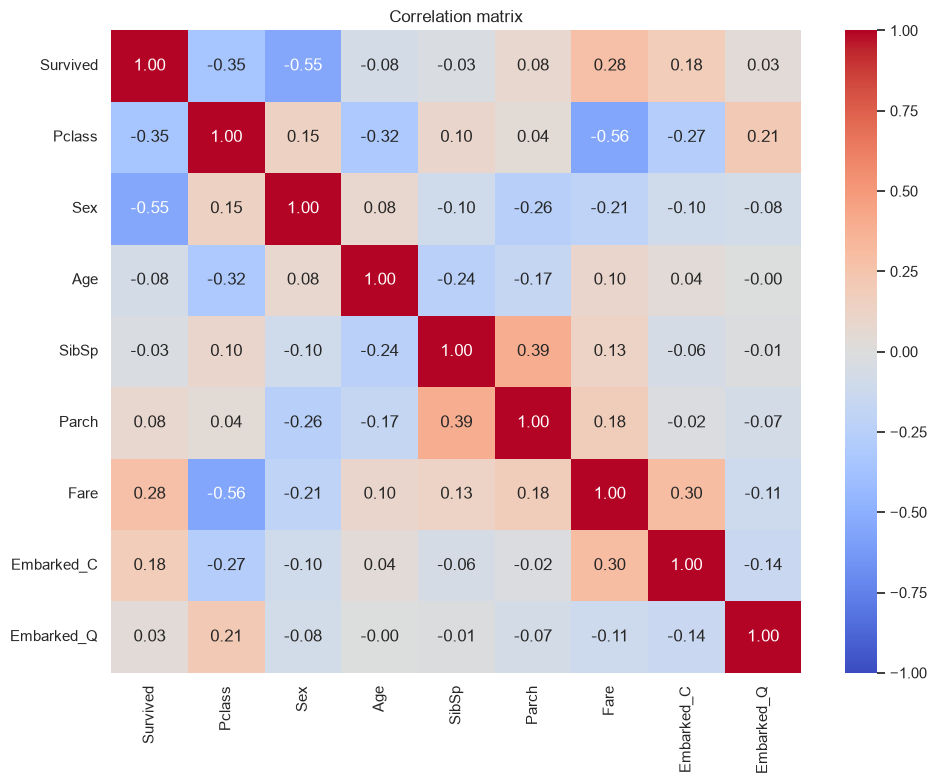

In [114]:
# Correlation matrix of all the variables (numeric after the temporary encoding)
corr = df_corr.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Correlation matrix")
plt.tight_layout()
plt.show()

## 3.2 Target vs features

**What we look for:** which features are related to `Survived`, because they are likely to be useful to predict it. We split them by the strength of the correlation (absolute value): high (≥ ≈ 0.7, keep), low (≤ ≈ 0.3, review or consider removing) and mid (the rest).

In [115]:
# Correlation of each feature with the target, sorted by strength (absolute value of the correlation)
target_corr = corr[target].drop(target).sort_values(key=abs, ascending=False)
target_corr

Sex          -0.549171
Pclass       -0.348007
Fare          0.275499
Embarked_C    0.180029
Parch         0.084178
Age          -0.076462
Embarked_Q    0.031501
SibSp        -0.026115
Name: Survived, dtype: float64

## 3.3 Features vs features

**What we look for:** pairs of **features** (without the target) that are strongly correlated, because they carry redundant information. This matters for the next part: if two features say almost the same thing, we may not need both.

We list the pairs of features with their correlation and split them with the same limits as before: above ≈ 0.7 there is a worrying redundancy (review it), and below ≈ 0.3 the features can be kept together.

In [116]:
# Correlation between the features (without the target)
corr_features = df_corr.drop(columns=target).corr()
corr_features

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked_C,Embarked_Q
Pclass,1.000000,0.145052,-0.315102,0.097900,0.040467,-0.556540,-0.272031,0.214760
Sex,0.145052,1.000000,0.078427,-0.100430,-0.256527,-0.206986,-0.100746,-0.081956
Age,-0.315102,0.078427,1.000000,-0.237664,-0.167355,0.101019,0.035810,-0.004636
SibSp,0.097900,-0.100430,-0.237664,1.000000,0.392269,0.127011,-0.058580,-0.010491
Parch,0.040467,-0.256527,-0.167355,0.392269,1.000000,0.177235,-0.022306,-0.072073
Fare,-0.556540,-0.206986,0.101019,0.127011,0.177235,1.000000,0.302360,-0.111737
Embarked_C,-0.272031,-0.100746,0.035810,-0.058580,-0.022306,0.302360,1.000000,-0.142505
Embarked_Q,0.214760,-0.081956,-0.004636,-0.010491,-0.072073,-0.111737,-0.142505,1.000000


## 3.4 Conclusions of the multivariate analysis

> **YOUR TURN:** write your conclusions about the correlation of each feature with the target and about the redundancy between features. Then decide the actions.

**Target vs features**
- ...

**Features vs features (redundancy)**
- ...

#### Actions decided from the conclusions

> **YOUR TURN:** for each finding, decide what you will do and where you will do it (order the rows by the "Where" column).

| What we found | Action decided | Where |
|---|---|---|
| | | |
| | | |
| | | |
| | | |

# 4. Features

Once the exploratory analysis is done, we prepare the variables for modeling. The conclusions of the EDA (skewness, outliers, imbalanced classes, relationship with `Survived`, redundancy between variables) guide the decisions of this part. Everything that is learned from the data is learned from the training set, and the same transformations are then applied to the test set.

## 4.1 Feature selection

Decision about which variables we keep for the model, based on what the EDA showed: relationship with `Survived`, imbalanced classes and redundancy between variables.

**How a feature selection is done**

Feature selection means keeping the variables that are useful for predicting the target and discarding those that add noise or redundancy. It is usually based on the following criteria, which come from the EDA:

1. **Redundancy between features (features vs features).** We look at the correlation between the input variables.
   - High correlation (|r| ≥ ≈ 0.7): the features may carry very similar information, so we review the redundancy and consider keeping only one of them.
   - Low or moderate correlation: we keep both features, because they provide different information.
2. **Correlation with the target (target vs features).** We look at the correlation between each variable and the target.
   - High (|r| ≥ ≈ 0.7): strong linear relationship, so we keep the feature.
   - Mid (between ≈ 0.3 and ≈ 0.7): we keep the feature.
   - Low (|r| ≤ ≈ 0.3): little linear relationship with the target, so we review it and consider removing it.
3. **Imbalanced classes.** A categorical variable where almost all the rows belong to the same class has almost no variation, so it can hardly help to distinguish between cases.

> **Note:** these limits are approximate and the correlation only measures **linear** relationships. A low correlation is a reason to review a variable, not to delete it automatically: we also check other evidence (for example, how much the performance of a model drops when we remove the variable) before deciding.

### 4.1.1 Decisions taken

> **YOUR TURN:** apply the criteria above to this dataset and write the decision for each candidate variable, with the evidence that supports it (the correlation, the differences in the data and, if you want to check it, the change in the accuracy of a simple model when you remove it).

| Variable | Correlation with `Survived` | Evidence | Decision |
|---|---|---|---|
| | | | |
| | | | |
| | | | |

### 4.1.2 Remove the variables decided

> **YOUR TURN:** write the variables that you have decided to remove. The same columns are removed from the test set.

In [117]:
# YOUR TURN: write the variables to remove (for example, removed_features = ["column_1", "column_2"])
removed_features = []

# Dataset with the selected features (the same columns are removed from the test set)
df_selected = df_clean.drop(columns=removed_features)
df_test_selected = df_test_clean.drop(columns=removed_features)

print(f"Features removed: {removed_features}")
print(f"Columns: {df_clean.shape[1]} -> {df_selected.shape[1]}")

Features removed: []
Columns: 12 -> 12


## 4.2 Feature engineering

Creation and transformation of variables on the selected features: encoding of the categorical variables, transformations, new variables...

**What is done in feature engineering**

Feature engineering means preparing the variables so that a model can use them, and creating new variables that make the useful information easier to see. It usually includes:

1. **Encoding categorical variables.** Models need numbers, and the encoding depends on the type of variable:
   - **Binary** (yes/no): mapped to 0/1.
   - **Ordinal**: mapped to integers that respect the order of the classes (for example 0, 1, 2).
   - **Nominal with more than two classes**: one-hot encoding (one 0/1 column per class), so we do not invent an order that does not exist.
2. **Transforming variables.** For example, a log transform to reduce the skewness of a variable, which we detected in the EDA.
3. **Creating new variables.** Combining the existing ones (ratios, sums, counts, flags) to give the model information that it cannot see directly. Each new variable should be justified by what the EDA showed and checked to see whether it really improves something.
4. **Scaling.** Standardizing or normalizing numerical variables so that they have a comparable range. It is needed for models and methods based on distances or gradients (for example KNN, neural networks, regularized regression or gradient descent), and it does not harm the others. It is done after separating `X` and `y` (section 4.4), with the scaler fitted on the training set only.

> **Note:** the new variables must be built only from the features, never from the target, and any transformation that learns from the data (like scaling) must be fitted on the training set only and then applied to the test set. Otherwise there is *data leakage*: information from the target or from the test set leaks into the model and the results look better than they really are.

### 4.2.1 Encoding

The model needs numbers, so we encode the categorical variables that remain in `df_selected`. We work on new dataframes (`df_encoded` for the training set and `df_test_encoded` for the test set) so that the previous ones are kept as they are. The encoding is a **fixed mapping**, it does not learn anything from the data, so the same one is applied to both sets.

> **YOUR TURN:** decide how to encode each type of variable, fill in the table and complete the function.

| Type | Variables | Encoding | Why |
|---|---|---|---|
| Binary (nominal) | | | |
| Ordinal | | | |
| Nominal with more than two classes | | | |

In [118]:
# YOUR TURN: complete the function so that all the categorical variables become numbers.
# The same function is applied to the training and to the test set.
def encode(data):
    data = data.copy()
    # ...
    return data

# For now, the function does nothing, so the notebook can run
df_encoded = encode(df_selected)
df_test_encoded = encode(df_test_selected)

**Check:** after the encoding there should be no text columns left (except `Name`, which we still need) and no new nulls (a null would mean that some class was not mapped).

In [119]:
for name, data in [("training", df_encoded), ("test", df_test_encoded)]:
    print(f"{name.capitalize()} set -> text columns: {data.select_dtypes(exclude='number').columns.tolist()}, nulls: {data.isna().sum().sum()}")
df_encoded.head()

Training set -> text columns: ['Name', 'Sex', 'Ticket', 'Cabin', 'Embarked'], nulls: 554
Test set -> text columns: ['Name', 'Sex', 'Ticket', 'Cabin', 'Embarked'], nulls: 135


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
692,693,1,3,"Lam, Mr. Ali",male,29.807687,0,0,1601,56.4958,NaN,S
481,482,0,2,"Frost, Mr. Anthony Wood ""Archie""",male,29.807687,0,0,239854,0.0000,NaN,S
527,528,0,1,"Farthing, Mr. John",male,29.807687,0,0,PC 17483,221.7792,C95,S
855,856,1,3,"Aks, Mrs. Sam (Leah Rosen)",female,18.000000,0,1,392091,9.3500,NaN,S
801,802,1,2,"Collyer, Mrs. Harvey (Charlotte Annie Tate)",female,31.000000,1,1,C.A. 31921,26.2500,NaN,S


### 4.2.2 Transformations

In the EDA we saw the skewness of the continuous variables. A transformation (for example, a log transform) can make their distribution more symmetric.

> **YOUR TURN:** look at the skewness of the continuous variables before and after the log transform (the cell below), decide which variables you transform (and which ones you do not) and why, and complete the function. The transformation is a fixed formula (it does not learn anything from the data), so the same function is applied to both sets. Remember that some variables have values equal to 0, and the log of 0 does not exist.

In [120]:
# Skewness before and after the log transform (closer to 0 means more symmetric). log1p is the log of 1 + the value, so it works with zeros
skewness = pd.DataFrame({
    "original": [df_encoded["Age"].skew(), df_encoded["Fare"].skew()],
    "log1p": [np.log1p(df_encoded["Age"]).skew(), np.log1p(df_encoded["Fare"]).skew()],
}, index=["Age", "Fare"])
display(skewness.round(2))

# YOUR TURN: complete the function with the transformations that you decide
def add_transformations(data):
    data = data.copy()
    # ...
    return data

# For now, the function does nothing, so the notebook can run. The same function is applied to both sets
df_encoded = add_transformations(df_encoded)
df_test_encoded = add_transformations(df_test_encoded)

,original,log1p
Age,0.39,-2.23
Fare,4.65,0.31


**Decision:** ...

**Why:** ...

### 4.2.3 New features

Here we combine the existing variables to build new ones that could give the model information that it cannot see directly. A new variable is only worth keeping if it is justified by the EDA **and** it improves the model.

> **YOUR TURN:** propose some candidate variables (sums, counts, flags, information extracted from a text column...), create them in a copy (`df_candidates`) and test them with a simple model (for example, a cross-validated logistic regression inside the training set). Remember that they must be built only from the features, never from the target. Hint: some columns still contain information that is not in a numeric form.

In [121]:
# YOUR TURN: create your candidate variables in a copy, so df_encoded is not modified yet (training set only)
df_candidates = df_encoded.copy()
# For example: df_candidates["FamilySize"] = df_candidates["SibSp"] + df_candidates["Parch"] + 1

# Then compare a simple model with the current features against the same model plus each new variable
# (for example, with stratified cross-validation inside the training set), looking at the accuracy.

**Decision:** ...

**Why:** ...

> **YOUR TURN (final step of the feature engineering):** if you decide to add a new variable, apply the same function to `df_encoded` and to `df_test_encoded`, so both sets have the same columns.

In [122]:
# YOUR TURN: apply to both sets the functions that create the new variables that you have decided to keep.
# For now, the dataframes are not changed, so the notebook can run.
df_encoded = df_encoded.copy()
df_test_encoded = df_test_encoded.copy()

## 4.3 Separate X and y

We separate each dataframe into the features (`X`) and the target (`y`):
- **Target (`y`):** `Survived`.
- **Features (`X`):** all the columns of the dataframe except the target, and the columns that you list in `not_features`. Keep **only one version of each variable**: for example, if you create a transformed version of a variable, the original one should not be a feature.

We do it for the training set and for the test set, with the same columns.

> **YOUR TURN:** write in `not_features` the columns that must not be features.
>
> **Safety net:** the model needs numeric features without nulls. If any of your previous steps is still pending (text columns or nulls), the cell below tells you what is missing and builds a **minimal baseline** (only the columns that are already numeric and have no nulls), so that the rest of the notebook can run. When you complete your steps, the cell uses your data.

In [123]:
# YOUR TURN: columns that must not be features (for example, the original version of a variable that you have transformed)
not_features = []

feature_columns = [c for c in df_encoded.columns if c not in [target] + not_features]

# Check that the previous steps are done
pending = []
text_columns = df_encoded[feature_columns].select_dtypes(exclude="number").columns.tolist()
if text_columns:
    pending.append(f"there are still text columns: {text_columns} (sections 2.1, 4.1 and 4.2)")
null_columns = df_encoded[feature_columns].columns[df_encoded[feature_columns].isna().any()].tolist()
if null_columns:
    pending.append(f"there are still nulls in {null_columns} (section 2.1)")

if not pending:
    # Your data is ready
    X_train, y_train = df_encoded[feature_columns], df_encoded[target]
    X_test, y_test = df_test_encoded[feature_columns], df_test_encoded[target]
else:
    # Minimal baseline so the notebook can run: only the numeric columns without nulls (and without the identifier)
    print("Some previous steps are still pending:")
    for message in pending:
        print(f"- {message}")
    numeric = df_encoded.select_dtypes("number")
    feature_columns = [c for c in numeric.columns if c not in [target, "PassengerId"] and not numeric[c].isna().any()]
    X_train, y_train = df_encoded[feature_columns], df_encoded[target]
    X_test, y_test = df_test_encoded[feature_columns], df_test_encoded[target]
    print("\nUsing a minimal baseline with these features:", feature_columns)

print(f"X_train: {X_train.shape[0]} rows x {X_train.shape[1]} columns")
print(f"X_test:  {X_test.shape[0]} rows x {X_test.shape[1]} columns")
print(f"Features: {feature_columns}")

Some previous steps are still pending:
- there are still text columns: ['Name', 'Sex', 'Ticket', 'Cabin', 'Embarked'] (sections 2.1, 4.1 and 4.2)
- there are still nulls in ['Cabin', 'Embarked'] (section 2.1)

Using a minimal baseline with these features: ['Pclass', 'Age', 'SibSp', 'Parch', 'Fare']
X_train: 712 rows x 5 columns
X_test:  179 rows x 5 columns
Features: ['Pclass', 'Age', 'SibSp', 'Parch', 'Fare']


## 4.4 Feature scaling

Scaling puts the features on a similar scale: each one is **standardized** (we subtract its mean and divide by its standard deviation, so it has mean 0 and standard deviation 1).

- **Not all the methods need it.** Gradient descent does (if not, the steps would be too big for some coefficients and too small for others, and it would take many more iterations to learn). The ready-made algorithm does not (its predictions are the same with or without scaling), and tree-based models do not either. Since it does not harm the ones that do not need it, we scale once and use the same matrices for all the methods.
- **It is learned from the training set only.** The mean and the standard deviation are calculated with `X_train`, and the same values are applied to `X_test`.
- **The coefficients change their units.** With scaled features, a coefficient is the change per standard deviation of the feature, not per unit. To read them in the original units (for example, the effect of one more bathroom) we undo the scaling: section 6.4.1 shows both.

In [124]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler().fit(X_train)  # the mean and the standard deviation are learned from the training set only
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)  # the same values are applied to the test set

print(f"Mean of the scaled training features (should be ≈ 0): {X_train_scaled.mean():.3f}")
print(f"Standard deviation of the scaled training features (should be ≈ 1): {X_train_scaled.std():.3f}")

Mean of the scaled training features (should be ≈ 0): -0.000
Standard deviation of the scaled training features (should be ≈ 1): 1.000


## 4.5 Train-validation strategy

To compare models and to tune them (sections 5 and 7) we need to measure the performance of each option **without touching the test set**. There are two ways to do it inside the training set:
- **A validation set:** we keep part of the training set apart and use it to compare the options.
- **Cross-validation:** we repeat the split several times (each time, a different part is used for validation) and average the results.

Since the training set is small (a few hundred passengers), a fixed validation set would depend a lot on which passengers fall in it, so we use **cross-validation** (stratified, to keep the proportion of survivors in every fold), as we already did to select the variables and to test the new ones. The **test set** stays apart until the final evaluation of the chosen model (section 6).

# 5. Model selection

*(To be developed.)* Here we would compare several models (for example, a logistic regression, a decision tree and a random forest) using cross-validation on the training set, and we would choose the best one. The test set is never used for this choice.

In this practice we work with a **logistic regression**, which is the simplest classification model and the best one to understand how a model learns.

# 6. Model training and evaluation

Once the data is prepared (`X_train`, `X_test`, `y_train`, `y_test`), we train a model to predict whether a passenger survived.

## 6.1 Logistic regression

**What it is:** despite its name, a logistic regression is a **classification** model. First, like a linear regression, it calculates a weighted sum of the features plus a constant (the intercept):

`score = intercept + w1 · feature1 + w2 · feature2 + ...`

Then it converts that score into a **probability** between 0 and 1 with the sigmoid function, `probability = 1 / (1 + e^(-score))`. If the probability of surviving is higher than 0.5, the model predicts "survived", and if not, "did not survive".

**Two ways to find the coefficients.** Training the model means looking for the weights (coefficients) that make the error of its predictions as small as possible (the loss, here the *log loss*, an error that is small when the model gives a high probability to what really happened and large when it is confident and wrong). There are two ways to do it, and both look for the same minimum:
- **A ready-made algorithm** (`LogisticRegression`): it finds the best coefficients by itself, with an optimizer that is much more efficient than the basic one. The logistic regression has no direct formula, so the optimizer also works in steps, but we do not see them.
- **Gradient descent:** the way a model "learns" step by step. We start from some coefficients and, in each iteration, we move them a little in the direction that reduces the error. It is like training the model by hand.

**What we do:**
1. **Train** the model in both ways, and compare how they learn.
2. **Read the coefficients:** a positive coefficient increases the probability of surviving and a negative one decreases it. If we apply `e^coefficient` we get an **odds ratio**: for example, a value of 0.5 means that the odds of surviving are halved when the feature grows by one unit, and a value of 2 means that they double.
3. **Evaluate** each model with the test set, which it has not seen, and compare with the training set to check that it generalizes.

> **Note:** gradient descent needs the features to be scaled and the ready-made algorithm does not, so we use for both the scaled features of section 4.4.

### 6.1.1 Training data

These are the data that both models use to learn: the features (`X_train`) and the target (`y_train`, survived or not).

In [125]:
X_train

,Pclass,Age,SibSp,Parch,Fare
692,3,29.807687,0,0,56.4958
481,2,29.807687,0,0,0.0000
527,1,29.807687,0,0,221.7792
855,3,18.000000,0,1,9.3500
801,2,31.000000,1,1,26.2500
...,...,...,...,...,...
359,3,29.807687,0,0,7.8792
258,1,35.000000,0,0,512.3292
736,3,48.000000,1,3,34.3750
462,1,47.000000,0,0,38.5000


In [126]:
y_train

692    1
481    0
527    0
855    1
801    1
      ..
359    1
258    1
736    0
462    0
507    1
Name: Survived, Length: 712, dtype: int64

## 6.2 Training with the ready-made algorithm (`LogisticRegression`)

The first way: the ready-made algorithm finds the best coefficients by itself.

### 6.2.1 Training

In [127]:
from sklearn.linear_model import LogisticRegression

# C is the inverse of the regularization strength: a very large C means practically no regularization,
# that is, a plain logistic regression that only minimizes the log loss
model = LogisticRegression(C=1e6, max_iter=2000)

# Some numpy builds raise harmless RuntimeWarnings in the matrix product: hide them only here
with np.errstate(divide="ignore", invalid="ignore", over="ignore"):
    model.fit(X_train_scaled, y_train)

# Learned weights: one coefficient per feature. They are in the scaled units (the change per standard deviation of the feature),
# so we also show them in the original units (undoing the scaling), which is how we read them
coef_original = model.coef_[0] / scaler.scale_
coefficients = pd.DataFrame({
    "coefficient (scaled)": model.coef_[0],
    "coefficient (original units)": coef_original,
    "odds ratio (original units)": np.exp(coef_original),
}, index=X_train.columns).sort_values("coefficient (original units)", ascending=False)
print(f"Intercept (scaled features): {model.intercept_[0]:.3f}\n")
coefficients.round(3)

Intercept (scaled features): -0.528



,coefficient (scaled),coefficient (original units),odds ratio (original units)
Parch,0.187,0.223,1.250
Fare,0.286,0.006,1.006
Age,-0.507,-0.039,0.962
SibSp,-0.225,-0.213,0.809
Pclass,-0.776,-0.931,0.394


In [128]:
# The model written as a formula: the score (log-odds) is a weighted sum of the features
terms = [f"{model.intercept_[0]:.3f}"]

for feature, coef in zip(X_train.columns, model.coef_[0]):
    sign = "+" if coef >= 0 else "-"
    terms.append(f" {sign} {abs(coef):.3f}·{feature}_scaled")

formula = "score = " + "".join(terms)
print(formula)

score = -0.528 - 0.776·Pclass_scaled - 0.507·Age_scaled - 0.225·SibSp_scaled + 0.187·Parch_scaled + 0.286·Fare_scaled


In [129]:
# The same model in the original units of the features (undoing the scaling)
coef_original = model.coef_[0] / scaler.scale_
intercept_original = model.intercept_[0] - np.sum(coef_original * scaler.mean_)

terms = [f"{intercept_original:.3f}"]

for feature, coef in zip(X_train.columns, coef_original):
    sign = "+" if coef >= 0 else "-"
    terms.append(f" {sign} {abs(coef):.3f}·{feature}")

print("score = " + "".join(terms))

score = 2.613 - 0.931·Pclass - 0.039·Age - 0.213·SibSp + 0.223·Parch + 0.006·Fare


### 6.2.2 Loss function

The coefficients that `LogisticRegression` has found are the ones with the **lowest loss**. We can check it.

- The **loss** measures the error of the model (here, the log loss). It is a function of the model parameters.
- The chart shows the loss as a function of **one** parameter (the coefficient of one feature (`Pclass`, if it is in your features)), keeping the others fixed.
- The **minimum** of the curve corresponds to the best value of the parameter: the one the model has learned.

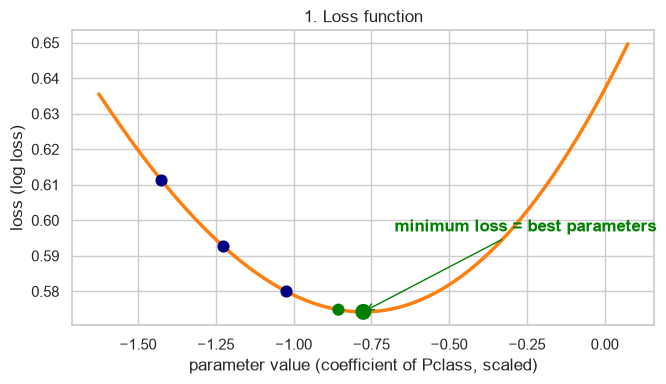

In [130]:
# 1. Loss function: error as a function of ONE parameter (the coefficient of one feature).
# The rest of the parameters stay fixed at the values learned by the model.
plot_feature = "Pclass" if "Pclass" in X_train.columns else X_train.columns[0]  # the feature whose coefficient we move
w_index = list(X_train.columns).index(plot_feature)
w_best = model.coef_[0][w_index]
w_values = np.linspace(w_best - 0.85, w_best + 0.85, 200)

def loss_for(w):
    coef = model.coef_[0].copy()
    coef[w_index] = w
    probability = 1 / (1 + np.exp(-(X_train_scaled @ coef + model.intercept_[0])))
    probability = np.clip(probability, 1e-12, 1 - 1e-12)
    return -np.mean(y_train.values * np.log(probability) + (1 - y_train.values) * np.log(1 - probability))  # log loss

with np.errstate(divide="ignore", invalid="ignore", over="ignore"):
    losses = [loss_for(w) for w in w_values]
    dots = [w_best - 0.65, w_best - 0.45, w_best - 0.25, w_best - 0.08, w_best]  # steps towards the minimum
    dot_losses = [loss_for(w) for w in dots]

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(w_values, losses, color="tab:orange", linewidth=2.5)
ax.scatter(dots[:3], dot_losses[:3], color="navy", s=60, zorder=3)
ax.scatter(dots[3:], dot_losses[3:], color="green", s=[60, 110], zorder=3)
ax.annotate("minimum loss = best parameters", xy=(w_best, dot_losses[-1]),
            xytext=(w_best + 0.1, dot_losses[-1] + (max(losses) - min(losses)) * 0.3),
            color="green", fontweight="bold", arrowprops=dict(arrowstyle="->", color="green"))
ax.set_xlabel(f"parameter value (coefficient of {plot_feature}, scaled)")
ax.set_ylabel("loss (log loss)")
ax.set_title("1. Loss function")
plt.tight_layout()
plt.show()

### 6.2.3 Evaluation

We evaluate the model on the training and the test set. In a classification problem, the model predicts a class (survived or not), so we count the hits and the mistakes with these metrics:

- **Accuracy:** proportion of passengers correctly classified.
- **Precision:** of the passengers that the model predicts as survivors, how many really survived.
- **Recall:** of the passengers that really survived, how many the model finds.
- **Specificity:** of the passengers that really did not survive, how many the model identifies correctly (the recall of the negative class).
- **F1:** a single number that combines precision and recall (it is low if either of them is low).

In [131]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

def evaluate_predictions(y_part, probability):
    predicted = (probability >= 0.5).astype(int)  # predicted class: 1 (survived) if the probability is at least 0.5
    return {
        "Accuracy": accuracy_score(y_part, predicted),
        "Precision": precision_score(y_part, predicted),
        "Recall": recall_score(y_part, predicted),
        "Specificity": recall_score(y_part, predicted, pos_label=0),  # the recall of the negative class (non-survivors)
        "F1": f1_score(y_part, predicted),
    }

def describe_results(results):
    # The same results in words (test set)
    test = results["test"]
    print("Results on the test set (passengers the model has not seen):")
    print(f"- Of every 100 passengers, we classify correctly {test['Accuracy'] * 100:.1f} (accuracy). A model that always predicts 'did not survive' would get {(1 - y_test.mean()) * 100:.1f}.")
    print(f"- When we predict that a passenger survived, we are right {test['Precision'] * 100:.1f}% of the times (precision).")
    print(f"- Of the passengers who really survived, we find {test['Recall'] * 100:.1f}% (recall).")
    print(f"- Of the passengers who really did not survive, we identify {test['Specificity'] * 100:.1f}% (specificity).")
    print(f"- Combining precision and recall, the F1 is {test['F1']:.3f}.")
    print()

def predict_probability_logistic(X_part):
    # Some numpy builds raise harmless RuntimeWarnings in the matrix product: hide them only here
    with np.errstate(divide="ignore", invalid="ignore", over="ignore"):
        return model.predict_proba(X_part)[:, 1]  # probability of surviving

results_lr = pd.DataFrame({
    "train": evaluate_predictions(y_train, predict_probability_logistic(X_train_scaled)),
    "test": evaluate_predictions(y_test, predict_probability_logistic(X_test_scaled)),
})
describe_results(results_lr)

results_lr.style.format("{:.3f}")

Results on the test set (passengers the model has not seen):
- Of every 100 passengers, we classify correctly 67.6 (accuracy). A model that always predicts 'did not survive' would get 61.5.
- When we predict that a passenger survived, we are right 62.2% of the times (precision).
- Of the passengers who really survived, we find 40.6% (recall).
- Of the passengers who really did not survive, we identify 84.5% (specificity).
- Combining precision and recall, the F1 is 0.491.



,train,test
Accuracy,0.711,0.676
Precision,0.681,0.622
Recall,0.462,0.406
Specificity,0.866,0.845
F1,0.550,0.491


**How to read the metrics** (the examples use the values of the test set, 179 passengers, 69 of whom really survived):

| Metric | What it means | Example |
|---|---|---|
| **Accuracy** | Proportion of passengers correctly classified. It is easy to understand, but it can be misleading if one class is much bigger than the other: here, always predicting "did not survive" already gets ≈ 61.5%. | An accuracy of ≈ 85.5% means that **of every 100 passengers we classify ≈ 85 correctly**, about 24 points more than the model that always predicts the majority class. |
| **Precision** | Of all the passengers that the model predicts as survivors, the proportion that really survived. It measures how much we can trust a "survived" prediction. | A precision of ≈ 84% means that, **when we say that a passenger survived, we are right in ≈ 84% of the cases** (53 of the 63 we predicted as survivors). |
| **Recall** | Of all the passengers that really survived, the proportion that the model finds. It measures how many survivors we are missing. | A recall of ≈ 77% means that **we find ≈ 77% of the survivors** (53 of 69) and we miss the other ≈ 23%. |
| **Specificity** | Of all the passengers that really did not survive, the proportion that the model identifies correctly. It measures how well we recognize the negatives (it is the counterpart of the recall). | A specificity of ≈ 91% means that **we correctly identify ≈ 91% of the non-survivors** (100 of 110) and we wrongly predict "survived" for the other ≈ 9%. |
| **F1** | A single number that combines precision and recall. It is low if either of them is low. | ≈ 0.80: both precision and recall are good and balanced. |

**Which one to use:** it depends on the cost of each mistake. Accuracy is a good first summary when the classes are not very imbalanced (here ≈ 62% / 38%), but we should always compare it with the majority-class baseline. Precision matters if a false "survived" is costly, and recall matters if missing a real survivor is costly. Recall and specificity are the two sides of the model: the survivors that it finds and the non-survivors that it recognizes. F1 summarizes the balance between precision and recall.

**Train vs test:** we compare both columns of the table. If the test performance is much worse than the training performance, the model is overfitting; if they are similar, it generalizes well.

**Confusion matrix:** it counts the hits and the mistakes of the model on the test set. Each row is the real class and each column is the predicted one:
- **Top left:** passengers who did not survive and that we predicted correctly.
- **Bottom right:** passengers who survived and that we predicted correctly.
- **Top right (false positives):** passengers who did not survive, but we predicted that they survived.
- **Bottom left (false negatives):** passengers who survived, but we predicted that they did not.

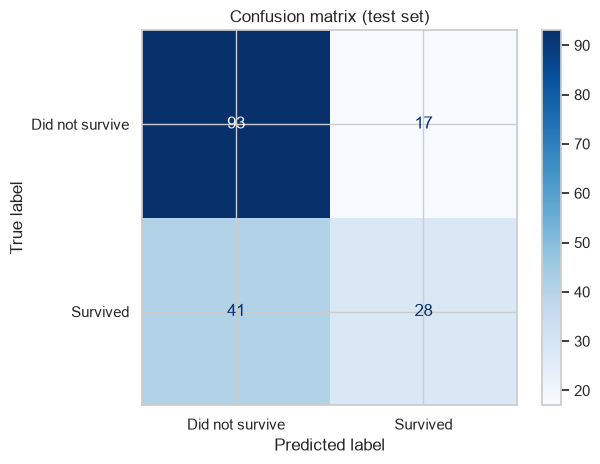

In [132]:
from sklearn.metrics import ConfusionMatrixDisplay

# Confusion matrix on the test set: rows = real class, columns = predicted class
with np.errstate(divide="ignore", invalid="ignore", over="ignore"):
    predicted_test = (predict_probability_logistic(X_test_scaled) >= 0.5).astype(int)

ConfusionMatrixDisplay.from_predictions(y_test, predicted_test, display_labels=["Did not survive", "Survived"], cmap="Blues")
plt.title("Confusion matrix (test set)")
plt.tight_layout()
plt.show()

## 6.3 Training with gradient descent

The second way: we train the model step by step, as a model "learns", and without using the ready-made algorithm.

### 6.3.1 Training

We use the scaled features of section 4.4. In each iteration the model:
1. calculates the probability of surviving of every passenger with the current coefficients, and the error (the loss),
2. calculates in which direction the error grows (the gradient), and
3. moves the coefficients a little **in the opposite direction**.

Two settings control the process (they are *hyperparameters*): the **learning rate** (how big each step is) and the number of **iterations** (how many steps we take). We start with all the coefficients and the intercept at 0, that is, with a probability of 0.5 for every passenger.

In [133]:
def sigmoid(score):
    return 1 / (1 + np.exp(-score))  # converts the score into a probability between 0 and 1

def gradient_descent(X, y, learning_rate, iterations):
    weights = np.zeros(X.shape[1])  # one coefficient per feature, starting at 0
    bias = 0.0
    loss_history = []
    # Some numpy builds raise harmless RuntimeWarnings in the matrix product: hide them only here
    with np.errstate(divide="ignore", invalid="ignore", over="ignore"):
        for iteration in range(iterations):
            probability = np.clip(sigmoid(X @ weights + bias), 1e-12, 1 - 1e-12)
            loss_history.append(-np.mean(y * np.log(probability) + (1 - y) * np.log(1 - probability)))  # log loss
            error = probability - y
            weights = weights - learning_rate * (X.T @ error) / len(y)  # step against the gradient
            bias = bias - learning_rate * error.mean()
    return weights, bias, loss_history

learning_rate = 0.5
iterations = 500
weights, bias, loss_history = gradient_descent(X_train_scaled, y_train.values.astype(float), learning_rate, iterations)
print(f"Loss at the start: {loss_history[0]:.4f}, at the end: {loss_history[-1]:.4f}")

Loss at the start: 0.6931, at the end: 0.5742


In [134]:
# The model written as a formula (with the scaled features)
terms = [f"{bias:.3f}"]

for feature, coef in zip(X_train.columns, weights):
    sign = "+" if coef >= 0 else "-"
    terms.append(f" {sign} {abs(coef):.3f}·{feature}_scaled")

formula = "score = " + "".join(terms)
print(formula)

score = -0.528 - 0.776·Pclass_scaled - 0.507·Age_scaled - 0.225·SibSp_scaled + 0.187·Parch_scaled + 0.286·Fare_scaled


### 6.3.2 Training loss curve

- It shows the loss **during the training**, as the iterations progress.
- It shows how the error decreases while the model learns, until it stops improving (it has reached the minimum).

The curve ends close to the minimum that `LogisticRegression` has found (dashed line).

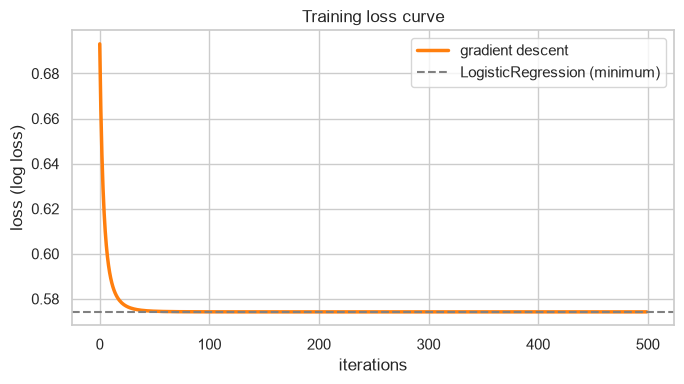

Loss at the end of gradient descent: 0.57421
Minimum loss of LogisticRegression:  0.57421


In [135]:
# Training loss curve: loss at each iteration, and the minimum found by the ready-made algorithm
probability_lr = np.clip(predict_probability_logistic(X_train_scaled), 1e-12, 1 - 1e-12)
y_values = y_train.values.astype(float)
ready_made_loss = -np.mean(y_values * np.log(probability_lr) + (1 - y_values) * np.log(1 - probability_lr))

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(loss_history, color="tab:orange", linewidth=2.5, label="gradient descent")
ax.axhline(ready_made_loss, color="gray", linestyle="--", label="LogisticRegression (minimum)")
ax.set_xlabel("iterations")
ax.set_ylabel("loss (log loss)")
ax.set_title("Training loss curve")
ax.legend()
plt.tight_layout()
plt.show()

print(f"Loss at the end of gradient descent: {loss_history[-1]:.5f}")
print(f"Minimum loss of LogisticRegression:  {ready_made_loss:.5f}")

### 6.3.3 Evaluation

We evaluate this model like the previous one, with the same metrics. The test set is scaled with the values of the training set.

In [136]:
def predict_probability_gradient_descent(X_scaled_part):
    with np.errstate(divide="ignore", invalid="ignore", over="ignore"):
        return sigmoid(X_scaled_part @ weights + bias)  # probability of surviving

results_gd = pd.DataFrame({
    "train": evaluate_predictions(y_train, predict_probability_gradient_descent(X_train_scaled)),
    "test": evaluate_predictions(y_test, predict_probability_gradient_descent(X_test_scaled)),
})
describe_results(results_gd)

results_gd.style.format("{:.3f}")

Results on the test set (passengers the model has not seen):
- Of every 100 passengers, we classify correctly 67.6 (accuracy). A model that always predicts 'did not survive' would get 61.5.
- When we predict that a passenger survived, we are right 62.2% of the times (precision).
- Of the passengers who really survived, we find 40.6% (recall).
- Of the passengers who really did not survive, we identify 84.5% (specificity).
- Combining precision and recall, the F1 is 0.491.



,train,test
Accuracy,0.711,0.676
Precision,0.681,0.622
Recall,0.462,0.406
Specificity,0.866,0.845
F1,0.550,0.491


## 6.4 Comparison of both ways of training

Both ways look for the same minimum of the loss, so we expect two models that are **very similar, but not identical**: the ready-made algorithm finds a very precise minimum, and gradient descent gets close to it after a number of iterations.

### 6.4.1 Coefficients

Both models use the same scaled features, so their coefficients can be compared directly. We also show them in the original units of the features (undoing the scaling), which is how we read them.

In [137]:
# Both models use the same scaled features, so their coefficients can be compared directly
coefficients_comparison = pd.DataFrame({"LogisticRegression": model.coef_[0], "gradient descent": weights}, index=X_train.columns)
coefficients_comparison["difference"] = coefficients_comparison["gradient descent"] - coefficients_comparison["LogisticRegression"]  # gradient descent minus the other way
display(coefficients_comparison.round(4))
print(f"Intercept (scaled features): LogisticRegression = {model.intercept_[0]:.4f}, gradient descent = {bias:.4f}\n")

# The same coefficients in the original units of the features (undoing the scaling), which is how we read them
coef_gd = weights / scaler.scale_
coef_lr = model.coef_[0] / scaler.scale_
coefficients_original = pd.DataFrame({"LogisticRegression": coef_lr, "gradient descent": coef_gd}, index=X_train.columns)
coefficients_original["difference"] = coefficients_original["gradient descent"] - coefficients_original["LogisticRegression"]
display(coefficients_original.round(4))
intercept_gd = bias - np.sum(coef_gd * scaler.mean_)
intercept_lr = model.intercept_[0] - np.sum(coef_lr * scaler.mean_)
print(f"Intercept (original units): LogisticRegression = {intercept_lr:.4f}, gradient descent = {intercept_gd:.4f}")

,LogisticRegression,gradient descent,difference
Pclass,-0.7759,-0.7759,-0.0000
Age,-0.5071,-0.5072,-0.0000
SibSp,-0.2253,-0.2254,-0.0001
Parch,0.1866,0.1866,0.0000
Fare,0.2857,0.2857,0.0001


Intercept (scaled features): LogisticRegression = -0.5282, gradient descent = -0.5280



,LogisticRegression,gradient descent,difference
Pclass,-0.9315,-0.9315,-0.0000
Age,-0.0390,-0.0390,-0.0000
SibSp,-0.2126,-0.2126,-0.0001
Parch,0.2228,0.2228,0.0000
Fare,0.0059,0.0059,0.0000


Intercept (original units): LogisticRegression = 2.6133, gradient descent = 2.6137


### 6.4.2 Evaluation

The metrics of both models, in the training and in the test set.

In [138]:
comparison = pd.concat({"LogisticRegression": results_lr, "gradient descent": results_gd}, axis=1)
comparison.style.format("{:.3f}")

### 6.4.3 How many iterations does the gradient descent need?

The result of gradient descent depends on how long we train it. We train it with different numbers of iterations (keeping the same learning rate) and compare it with the ready-made algorithm: the more iterations, the closer it gets.

In [139]:
rows = []
for n_iterations in [10, 100, 500, 2000]:
    w, b, _ = gradient_descent(X_train_scaled, y_train.values.astype(float), learning_rate, n_iterations)
    with np.errstate(divide="ignore", invalid="ignore", over="ignore"):
        metrics = evaluate_predictions(y_test, sigmoid(X_test_scaled @ w + b))
    rows.append({
        "iterations": n_iterations,
        "max coefficient difference": np.abs((w - model.coef_[0]) / scaler.scale_).max(),
        "Accuracy (test)": metrics["Accuracy"],
        "F1 (test)": metrics["F1"],
    })

# Reference: the ready-made algorithm
rows.append({
    "iterations": "LogisticRegression",
    "max coefficient difference": 0.0,
    "Accuracy (test)": results_lr.loc["Accuracy", "test"],
    "F1 (test)": results_lr.loc["F1", "test"],
})
pd.DataFrame(rows).set_index("iterations").style.format({"max coefficient difference": "{:.4f}", "Accuracy (test)": "{:.3f}", "F1 (test)": "{:.3f}"})

,max coefficient difference,Accuracy (test),F1 (test)
iterations,,,
10,0.3906,0.665,0.464
100,0.0182,0.676,0.491
500,0.0001,0.676,0.491
2000,0.0001,0.676,0.491
LogisticRegression,0.0000,0.676,0.491


**Conclusions of the comparison**

> **YOUR TURN:** write your conclusions: how different are the coefficients and the metrics of both ways of training? What happens with few iterations? When would you use each one?

- ...

## 6.5 Conclusions of the logistic regression

> **YOUR TURN:** write your conclusions about the model (use the coefficients and the metrics of the test set). Compare it with the baseline: what have you improved with your cleaning, selection and feature engineering?

**Coefficients**
- ...

**Performance**
- ...

**Limitations**
- ...

# 7. Hyperparameter tuning

*(To be developed.)* Hyperparameters are the settings of a model that are not learned from the data (for example, the strength of the regularization of a logistic regression, `C`). Here we would try different values and choose the best ones using cross-validation on the training set.

# 8. Deployment

*(To be developed.)* Once the model is chosen and evaluated, it is saved together with the preprocessing steps (cleaning, encoding, transformations) so that it can estimate the survival of new passengers.